run pip install yfinance

In [2]:
import numpy as np
import pandas as pd
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [3]:
import yfinance as yf
from datetime import datetime

# use datetime to specify smart date
startDate = datetime(2023, 1, 2)

# use datetime to specify end data
endDate = datetime(2024, 1, 30)

# specify which stock using Ticker() then pass the stock symbot for Meta
stock = yf.download("Meta", start=startDate, end=endDate)
stock

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,META,META,META,META,META
Date,,,,,
2023-01-03,123.768730,125.386043,121.327885,121.863682,35528500
2023-01-04,126.378250,128.045169,124.870081,126.388167,32397100
2023-01-05,125.951599,127.519298,123.570285,125.147901,25447100
2023-01-06,129.007629,129.315213,125.058616,127.965802,27584500
2023-01-09,128.461899,131.914798,128.273376,130.138742,26649100
...,...,...,...,...,...
2024-01-23,382.200714,385.355946,379.104982,381.625213,15506100
2024-01-24,387.657867,393.065413,384.790356,386.963306,15698500


In [4]:
stock.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 269 entries, 2023-01-03 to 2024-01-29
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, META)   269 non-null    float64
 1   (High, META)    269 non-null    float64
 2   (Low, META)     269 non-null    float64
 3   (Open, META)    269 non-null    float64
 4   (Volume, META)  269 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 12.6 KB


In [5]:
stock.index

DatetimeIndex(['2023-01-03', '2023-01-04', '2023-01-05', '2023-01-06',
               '2023-01-09', '2023-01-10', '2023-01-11', '2023-01-12',
               '2023-01-13', '2023-01-17',
               ...
               '2024-01-16', '2024-01-17', '2024-01-18', '2024-01-19',
               '2024-01-22', '2024-01-23', '2024-01-24', '2024-01-25',
               '2024-01-26', '2024-01-29'],
              dtype='datetime64[s]', name='Date', length=269, freq=None)

In [6]:
# retrieve all 2024 data
stock.loc['2024']

Price,Close,High,Low,Open,Volume
Ticker,META,META,META,META,META
Date,,,,,
2024-01-02,343.593689,350.410192,337.362588,348.584523,19042200
2024-01-03,341.787872,345.240787,340.507908,342.293911,15451100
2024-01-04,344.417206,345.439185,340.726170,341.817611,12099900
2024-01-05,349.209656,350.747575,343.563957,344.288254,13920700
2024-01-08,355.867279,356.184795,349.308732,351.938122,13890200
2024-01-09,354.646912,357.831939,352.593022,353.624933,13463900
2024-01-10,367.585388,370.036157,356.284060,357.365600,22117200
2024-01-11,366.791656,369.877427,360.104115,369.232494,17205400


In [7]:
# cehck for duplicates indeces 
stock.index.is_unique

True

BM has been deprecated by pandas and the correct form is BME

In [8]:
# Generate end-of-month business dates
end_of_month_dates = pd.date_range(start = stock.index.min(), end = stock.index.max(), freq='BME')

# Filter DataFrame to get only the rows correspoidning to the end-of-month buseiness dates
end_of_month_df = stock[stock.index.isin(end_of_month_dates)]
end_of_month_df

Price,Close,High,Low,Open,Volume
Ticker,META,META,META,META,META
Date,,,,,
2023-01-31,147.810043,148.712961,146.371337,146.797981,29842100
2023-02-28,173.577835,176.167513,170.531732,170.561498,46051100
2023-03-31,210.289749,210.517954,205.160007,205.626348,25440300
2023-04-28,238.448792,238.557920,233.914368,237.148979,39554000
2023-05-31,262.658813,262.936632,256.437644,257.975564,25473700
2023-06-30,284.745483,286.799343,282.205419,282.542768,19694900
2023-07-31,316.119263,323.124288,315.117117,321.169626,25799600
2023-08-31,293.586090,298.755514,293.357870,293.496764,17229900


In [9]:
# move 2 steps forward
stock.shift(2)

Price,Close,High,Low,Open,Volume
Ticker,META,META,META,META,META
Date,,,,,
2023-01-03,NaN,NaN,NaN,NaN,NaN
2023-01-04,NaN,NaN,NaN,NaN,NaN
2023-01-05,123.768730,125.386043,121.327885,121.863682,35528500.0
2023-01-06,126.378250,128.045169,124.870081,126.388167,32397100.0
2023-01-09,125.951599,127.519298,123.570285,125.147901,25447100.0
...,...,...,...,...,...
2024-01-23,380.464325,381.367213,375.026983,376.048962,21670800.0
2024-01-24,378.807281,387.310559,378.192114,384.929252,17680500.0


In [10]:
# move 2 steps backward
stock.shift(-2)

Price,Close,High,Low,Open,Volume
Ticker,META,META,META,META,META
Date,,,,,
2023-01-03,125.951599,127.519298,123.570285,125.147901,25447100.0
2023-01-04,129.007629,129.315213,125.058616,127.965802,27584500.0
2023-01-05,128.461899,131.914798,128.273376,130.138742,26649100.0
2023-01-06,131.954483,132.400976,126.159952,126.279013,28684400.0
2023-01-09,131.855286,132.807818,129.325138,129.940320,25423000.0
...,...,...,...,...,...
2024-01-23,390.118561,392.410572,382.657125,387.132018,15091100.0
2024-01-24,391.071106,393.700466,388.540943,391.279462,13163700.0


In [11]:
# move 2 steps backward, and with daily frequency
stock.shift(-2, freq='D')

Price,Close,High,Low,Open,Volume
Ticker,META,META,META,META,META
Date,,,,,
2023-01-01,123.768730,125.386043,121.327885,121.863682,35528500
2023-01-02,126.378250,128.045169,124.870081,126.388167,32397100
2023-01-03,125.951599,127.519298,123.570285,125.147901,25447100
2023-01-04,129.007629,129.315213,125.058616,127.965802,27584500
2023-01-07,128.461899,131.914798,128.273376,130.138742,26649100
...,...,...,...,...,...
2024-01-21,382.200714,385.355946,379.104982,381.625213,15506100
2024-01-22,387.657867,393.065413,384.790356,386.963306,15698500


 forward fill the missing values
 
stock_shifted= stock.shift(-2).fillna(method='ffill')
this no longer works

In [12]:
# forward fill the missing values
stock_shifted= stock.shift(-2).ffill()
stock_shifted

Price,Close,High,Low,Open,Volume
Ticker,META,META,META,META,META
Date,,,,,
2023-01-03,125.951599,127.519298,123.570285,125.147901,25447100.0
2023-01-04,129.007629,129.315213,125.058616,127.965802,27584500.0
2023-01-05,128.461899,131.914798,128.273376,130.138742,26649100.0
2023-01-06,131.954483,132.400976,126.159952,126.279013,28684400.0
2023-01-09,131.855286,132.807818,129.325138,129.940320,25423000.0
...,...,...,...,...,...
2024-01-23,390.118561,392.410572,382.657125,387.132018,15091100.0
2024-01-24,391.071106,393.700466,388.540943,391.279462,13163700.0


In [13]:
# Resample date into weekly (every Friday) and get the mean
stock.resample('W-FRI').mean()

Price,Close,High,Low,Open,Volume
Ticker,META,META,META,META,META
Date,,,,,
2023-01-06,126.276552,127.566431,123.706717,125.341388,30239300.0
2023-01-13,132.766125,134.010359,129.656524,130.535630,26787600.0
2023-01-20,134.916241,136.774162,132.410904,134.040613,24669225.0
2023-01-27,144.257941,145.385091,141.096746,141.854796,27463260.0
2023-02-03,163.606100,168.380635,159.663044,161.183117,68165720.0
2023-02-10,181.213928,186.704841,179.285071,183.478166,39251200.0
2023-02-17,174.905441,176.560453,172.351484,173.591751,26161100.0
2023-02-24,170.072865,172.481465,168.331536,170.169609,24208725.0


In [14]:
# Monthly resample and get average, then label with right bin
stock.resample("BME", closed='right').mean()

Price,Close,High,Low,Open,Volume
Ticker,META,META,META,META,META
Date,,,,,
2023-01-31,136.180825,137.649796,133.520699,134.726238,2.743853e+07
2023-02-28,175.104817,178.812565,172.416966,174.631691,4.064057e+07
2023-03-31,192.433788,195.017859,189.068891,191.616722,3.000230e+07
2023-04-28,215.510895,217.449366,212.912340,214.998597,2.350989e+07
2023-05-31,241.467365,244.122436,238.073995,240.269941,2.214227e+07
2023-06-30,274.905069,278.466172,270.858729,273.680870,2.291193e+07
2023-07-31,300.780624,305.656859,296.567187,301.950447,3.125700e+07
2023-08-31,297.523016,301.867618,293.651655,298.075204,1.845678e+07


M is no longer supported by pandas resample, so we can use ME instead

In [15]:
# Monthly resample and get average, then label with right bin
stock.resample("ME", closed='right', label='right').mean()

Price,Close,High,Low,Open,Volume
Ticker,META,META,META,META,META
Date,,,,,
2023-01-31,136.180825,137.649796,133.520699,134.726238,2.743853e+07
2023-02-28,175.104817,178.812565,172.416966,174.631691,4.064057e+07
2023-03-31,192.433788,195.017859,189.068891,191.616722,3.000230e+07
2023-04-30,215.510895,217.449366,212.912340,214.998597,2.350989e+07
2023-05-31,241.467365,244.122436,238.073995,240.269941,2.214227e+07
2023-06-30,274.905069,278.466172,270.858729,273.680870,2.291193e+07
2023-07-31,300.780624,305.656859,296.567187,301.950447,3.125700e+07
2023-08-31,297.523016,301.867618,293.651655,298.075204,1.845678e+07


TO DO:
Try changing the label to ‘left’ and compare the date indices. Because we are computing the monthly mean, the values will not change. Try to calculate the sum for different labels and close settings. Do you notice any changes?


The differences is whether it includes the right or the left values. In the left closed it picked the end date of the previous month as part of the data points. This is similiar to when we have values from 0,1,2,3,4,5. Picking five values, Left closed picks the values 0,1,2,3,4 and Right closed will pick values 1,2,3,4,5. 

Now the label part is where we want our index to be picked from, the beginning or the ending. Label left picks the first value in the sample for the index, while Right label picks the last value in the sample as the index.

When we have label left and close left we see the pick of the sample as the last day in the month prior. See the following cell.
When we have label right and close right we see the pick include the last ME of that sample. 

In [16]:
# Monthly resample and get sum, then label with left bin
stock.resample("ME", closed='left', label='left').sum()

Price,Close,High,Low,Open,Volume
Ticker,META,META,META,META,META
Date,,,,,
2022-12-31,2575.806450,2604.282956,2524.042636,2547.726786,518928500
2023-01-31,3301.223740,3369.984176,3251.761959,3294.238621,755961900
2023-02-28,4389.265213,4451.060307,4313.956208,4372.119765,710663800
2023-03-31,4304.996750,4342.055905,4250.494461,4290.599689,472128200
2023-04-30,5049.623215,5107.756962,4981.190240,5027.963144,461656300
2023-05-31,5750.919769,5823.926895,5662.265537,5722.731069,486929300
2023-06-30,5984.238708,6076.812228,5898.432035,6000.382076,619035200
2023-07-31,6865.562531,6967.323987,6775.747307,6883.402544,433075600


In [17]:
# Monthly resample and get sum, then label with right bin
stock.resample("ME", closed='right', label='right').sum()

Price,Close,High,Low,Open,Volume
Ticker,META,META,META,META,META
Date,,,,,
2023-01-31,2723.616493,2752.995917,2670.413973,2694.524768,548770600
2023-02-28,3326.991531,3397.438728,3275.922354,3318.002138,772170900
2023-03-31,4425.977127,4485.410748,4348.584482,4407.184616,690053000
2023-04-30,4094.707001,4131.537951,4045.334454,4084.973341,446687900
2023-05-31,5312.282028,5370.693594,5237.627884,5285.938708,487130000
2023-06-30,5773.006439,5847.789605,5688.033311,5747.298273,481150500
2023-07-31,6015.612488,6113.137174,5931.343734,6039.008935,625139900
2023-08-31,6843.029358,6942.955213,6753.988060,6855.729682,424505900


In [18]:
# Monthly resample and get sum, then label with right bin
stock.resample("ME", closed='left', label='right').sum()

Price,Close,High,Low,Open,Volume
Ticker,META,META,META,META,META
Date,,,,,
2023-01-31,2575.806450,2604.282956,2524.042636,2547.726786,518928500
2023-02-28,3301.223740,3369.984176,3251.761959,3294.238621,755961900
2023-03-31,4389.265213,4451.060307,4313.956208,4372.119765,710663800
2023-04-30,4304.996750,4342.055905,4250.494461,4290.599689,472128200
2023-05-31,5049.623215,5107.756962,4981.190240,5027.963144,461656300
2023-06-30,5750.919769,5823.926895,5662.265537,5722.731069,486929300
2023-07-31,5984.238708,6076.812228,5898.432035,6000.382076,619035200
2023-08-31,6865.562531,6967.323987,6775.747307,6883.402544,433075600


In [19]:
# Monthly resample and get sum, then label with left bin
stock.resample("ME", closed='right', label='left').sum()

Price,Close,High,Low,Open,Volume
Ticker,META,META,META,META,META
Date,,,,,
2022-12-31,2723.616493,2752.995917,2670.413973,2694.524768,548770600
2023-01-31,3326.991531,3397.438728,3275.922354,3318.002138,772170900
2023-02-28,4425.977127,4485.410748,4348.584482,4407.184616,690053000
2023-03-31,4094.707001,4131.537951,4045.334454,4084.973341,446687900
2023-04-30,5312.282028,5370.693594,5237.627884,5285.938708,487130000
2023-05-31,5773.006439,5847.789605,5688.033311,5747.298273,481150500
2023-06-30,6015.612488,6113.137174,5931.343734,6039.008935,625139900
2023-07-31,6843.029358,6942.955213,6753.988060,6855.729682,424505900


In [21]:
# upsample and fill forward each 4-hour value
upsample_4H = stock.resample('4h').ffill()
upsample_4H.head(20)

Price,Close,High,Low,Open,Volume
Ticker,META,META,META,META,META
Date,,,,,
2023-01-03 00:00:00,123.768730,125.386043,121.327885,121.863682,35528500
2023-01-03 04:00:00,123.768730,125.386043,121.327885,121.863682,35528500
2023-01-03 08:00:00,123.768730,125.386043,121.327885,121.863682,35528500
2023-01-03 12:00:00,123.768730,125.386043,121.327885,121.863682,35528500
2023-01-03 16:00:00,123.768730,125.386043,121.327885,121.863682,35528500
2023-01-03 20:00:00,123.768730,125.386043,121.327885,121.863682,35528500
2023-01-04 00:00:00,126.378250,128.045169,124.870081,126.388167,32397100
2023-01-04 04:00:00,126.378250,128.045169,124.870081,126.388167,32397100


A-DEC is not working anymore and the correct version is YE-DEC

In [27]:
# annual period resampling
annual_stock = stock.resample("YE-DEC").mean()
annual_stock

Price,Close,High,Low,Open,Volume
Ticker,META,META,META,META,META
Date,,,,,
2023-12-31,259.388732,262.706734,255.751317,258.847738,2.423055e+07
2024-12-31,368.789109,371.850870,363.879737,367.321154,1.623367e+07


In [28]:
# Using the rolling operator, compute the 10 day moving average
sma_10 = stock.rolling(window=10).mean()
sma_10.head(20)

Price,Close,High,Low,Open,Volume
Ticker,META,META,META,META,META
Date,,,,,
2023-01-03,NaN,NaN,NaN,NaN,NaN
2023-01-04,NaN,NaN,NaN,NaN,NaN
2023-01-05,NaN,NaN,NaN,NaN,NaN
2023-01-06,NaN,NaN,NaN,NaN,NaN
2023-01-09,NaN,NaN,NaN,NaN,NaN
2023-01-10,NaN,NaN,NaN,NaN,NaN
2023-01-11,NaN,NaN,NaN,NaN,NaN
2023-01-12,NaN,NaN,NaN,NaN,NaN


<Axes: xlabel='Date'>

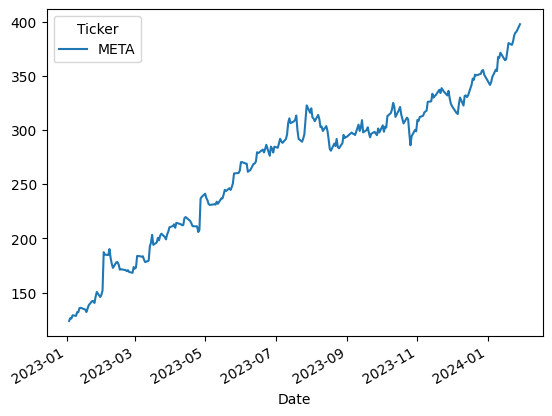

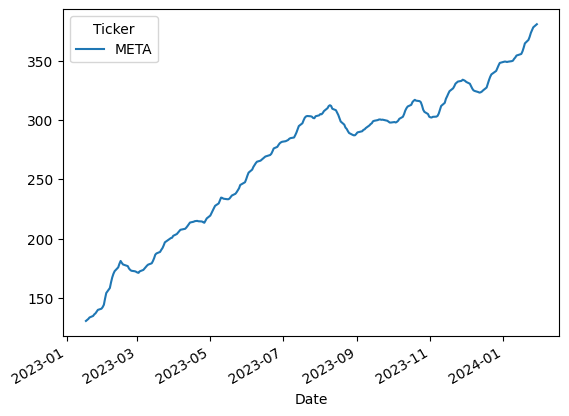

In [31]:
stock['Close'].plot()
sma_10['Close'].plot()

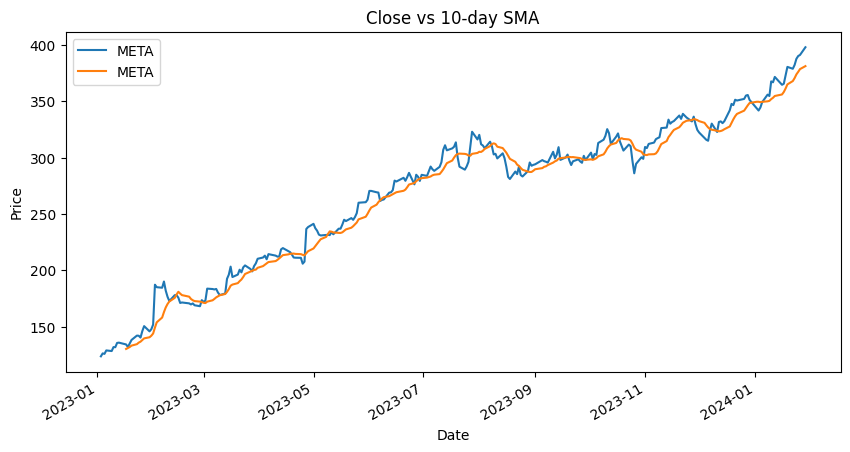

In [33]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))
stock["Close"].plot(ax=ax, label="Close Price")
sma_10["Close"].plot(ax=ax, label="10-day SMA")

ax.set_title("Close vs 10-day SMA")
ax.set_xlabel("Date")
ax.set_ylabel("Price")
ax.legend()
plt.show()

In [34]:
change_std = stock.pct_change().rolling(10, min_periods=3).std()
change_std

Price,Close,High,Low,Open,Volume
Ticker,META,META,META,META,META
Date,,,,,
2023-01-03,NaN,NaN,NaN,NaN,NaN
2023-01-04,NaN,NaN,NaN,NaN,NaN
2023-01-05,NaN,NaN,NaN,NaN,NaN
2023-01-06,0.015124,0.013054,0.019861,0.024021,0.149843
2023-01-09,0.015345,0.011712,0.017958,0.019614,0.123889
...,...,...,...,...,...
2024-01-23,0.015875,0.015697,0.015494,0.015994,0.291829
2024-01-24,0.015532,0.016077,0.015638,0.016038,0.290921


<Axes: xlabel='Date'>

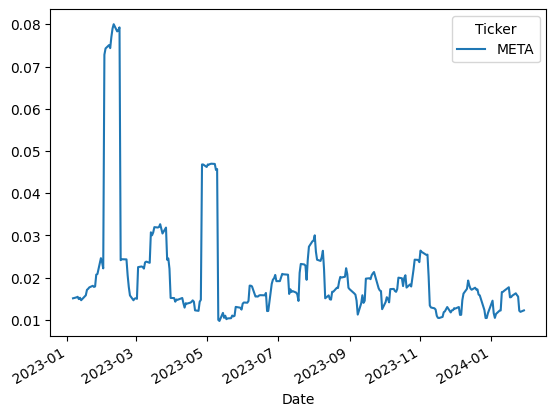

In [36]:
change_std['Close'].plot()

In [38]:
expanding_mean = change_std.expanding().mean()
expanding_mean

Price,Close,High,Low,Open,Volume
Ticker,META,META,META,META,META
Date,,,,,
2023-01-03,NaN,NaN,NaN,NaN,NaN
2023-01-04,NaN,NaN,NaN,NaN,NaN
2023-01-05,NaN,NaN,NaN,NaN,NaN
2023-01-06,0.015124,0.013054,0.019861,0.024021,0.149843
2023-01-09,0.015234,0.012383,0.018910,0.021818,0.136866
...,...,...,...,...,...
2024-01-23,0.021080,0.019613,0.019352,0.022225,0.388043
2024-01-24,0.021058,0.019600,0.019338,0.022201,0.387674


change_std['Close'].plot()

expanding_mean['Close'].plot()

doesn't give the same graph as the HoS

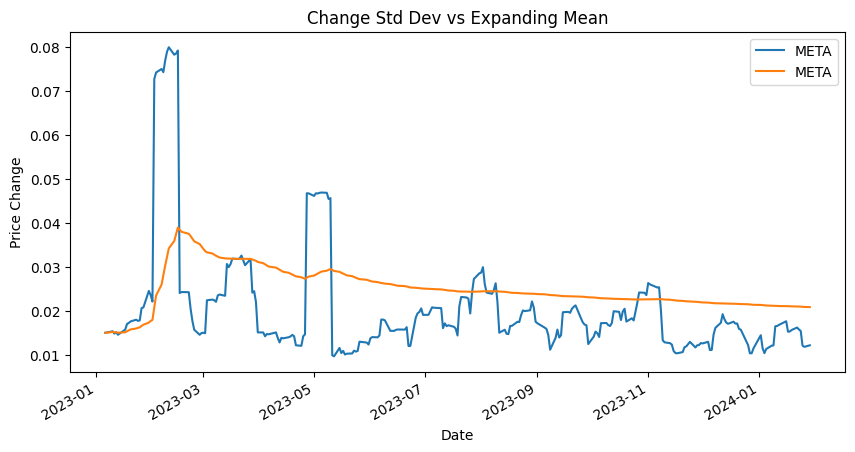

In [40]:
fig, ax = plt.subplots(figsize=(10, 5))
change_std["Close"].plot(ax=ax, label="Change Std Dev")
expanding_mean["Close"].plot(ax=ax, label="Expanding Mean")

ax.set_title("Change Std Dev vs Expanding Mean")
ax.set_xlabel("Date")
ax.set_ylabel("Price Change")
ax.legend()
plt.show()

In [41]:
# exponentially weighted moving average with span andindow size of 10.
ewm_10 = stock.ewm(span=10).mean()
ewm_10

Price,Close,High,Low,Open,Volume
Ticker,META,META,META,META,META
Date,,,,,
2023-01-03,123.768730,125.386043,121.327885,121.863682,3.552850e+07
2023-01-04,125.203966,126.848563,123.276093,124.352149,3.380623e+07
2023-01-05,125.504510,127.118194,123.394356,124.672036,3.044592e+07
2023-01-06,126.658632,127.842014,123.942656,125.757185,2.950321e+07
2023-01-09,127.176301,129.011199,125.185888,127.015011,2.868387e+07
...,...,...,...,...,...
2024-01-23,370.852033,374.231348,366.623032,370.208744,1.676210e+07
2024-01-24,373.907639,377.655723,369.926182,373.255028,1.656872e+07


Code as written in the HoS doesn't work to get the same result.

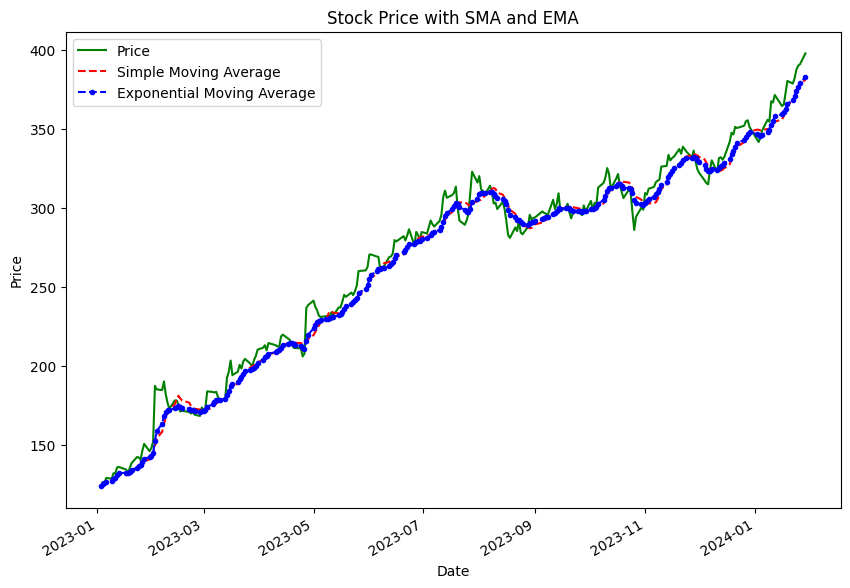

In [ ]:
#rename for the legend by converting to series and renaming
price = stock["Close"].squeeze().rename("Price")
sma = sma_10["Close"].squeeze().rename("SMA 10")
ema = ewm_10["Close"].squeeze().rename("EMA 10")

fig, ax = plt.subplots(figsize=(10, 7))
price.plot(ax=ax, style='g-', label='Price')
sma.plot(ax=ax, style='r--', label='Simple Moving Average')
ema.plot(ax=ax, style='b--.', label='Exponential Moving Average')
ax.set_title("Stock Price with SMA and EMA")
ax.set_xlabel("Date")
ax.set_ylabel("Price")
ax.legend()
plt.show()  